# Cyberbullying Classification

This is an NLP classification project.

The file is a list of tweets. Each row is one of six labels: age, ethnicity, gender, religion, other cyberbullying, or not cyberbullying. The classes are already balanced.

I will plot class counts, the most common words and a word cloud, then train two models on the same split. The first is Logistic Regression on TF-IDF, a usual baseline for multiclass text. The second is a Bidirectional LSTM with a learned embedding. Tweets are short and the insult often sits in word order, so the deep model is the one I want here. I will compare accuracy and macro F1, plot the confusion matrices, and save the LSTM.


In [3]:
import kagglehub

path = kagglehub.dataset_download("andrewmvd/cyberbullying-classification")
print("Path to dataset files:", path)


Path to dataset files: C:\Users\Administrator\.cache\kagglehub\datasets\andrewmvd\cyberbullying-classification\versions\1


In [4]:
import os
import glob
import pandas as pd

csv_path = glob.glob(os.path.join(path, "**", "cyberbullying_tweets.csv"), recursive=True)[0]
df = pd.read_csv(csv_path)
df = df.rename(columns={"tweet_text": "text", "cyberbullying_type": "label"})
df = df.dropna(subset=["text", "label"])
df.head()


,text,label
0,"In other words #katandandre, your food was cra...",not_cyberbullying
1,Why is #aussietv so white? #MKR #theblock #ImA...,not_cyberbullying
2,@XochitlSuckkks a classy whore? Or more red ve...,not_cyberbullying
3,"@Jason_Gio meh. :P thanks for the heads up, b...",not_cyberbullying
4,@RudhoeEnglish This is an ISIS account pretend...,not_cyberbullying


In [5]:
print(df.shape)
print(df["label"].value_counts())


(47692, 2)
label
religion               7998
age                    7992
gender                 7973
ethnicity              7961
not_cyberbullying      7945
other_cyberbullying    7823
Name: count, dtype: int64


In [6]:
df["text"] = df["text"].str.lower()
df["text"] = df["text"].str.replace(r"http\S+", " ", regex=True)
df["text"] = df["text"].str.replace(r"@\w+", " ", regex=True)
df["text"] = df["text"].str.replace(r"[^\w\s]", " ", regex=True)
df["text"] = df["text"].str.replace(r"\d+", " ", regex=True)
df["length"] = df["text"].str.split().str.len()
df.head()


,text,label,length
0,in other words katandandre your food was cra...,not_cyberbullying,9
1,why is aussietv so white mkr theblock ima...,not_cyberbullying,14
2,a classy whore or more red velvet cupcakes,not_cyberbullying,8
3,meh p thanks for the heads up but not to...,not_cyberbullying,17
4,this is an isis account pretending to be a k...,not_cyberbullying,17


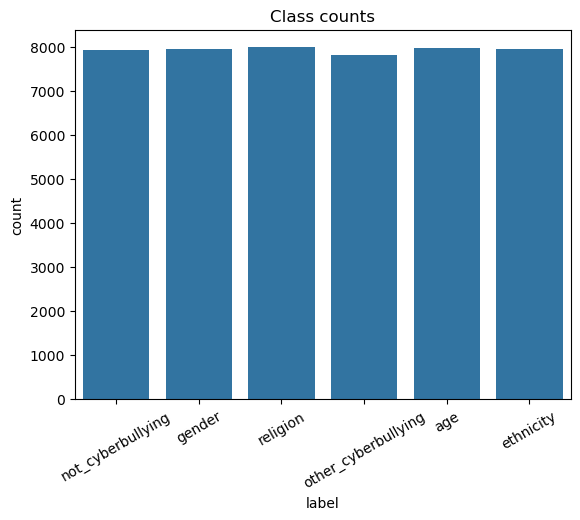

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=df, x="label")
plt.xticks(rotation=30)
plt.title("Class counts")
plt.show()


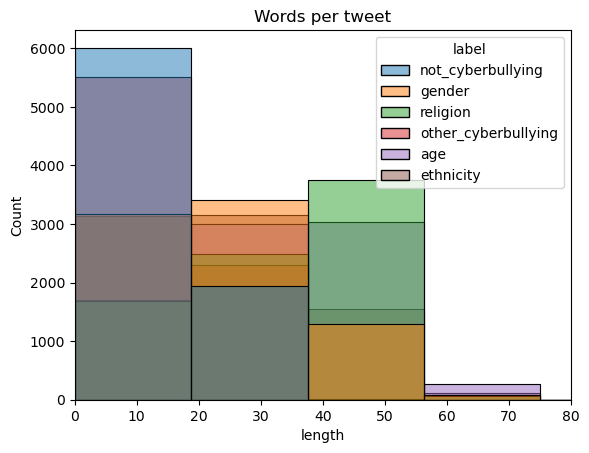

In [8]:
sns.histplot(data=df, x="length", hue="label", bins=40)
plt.xlim(0, 80)
plt.title("Words per tweet")
plt.show()


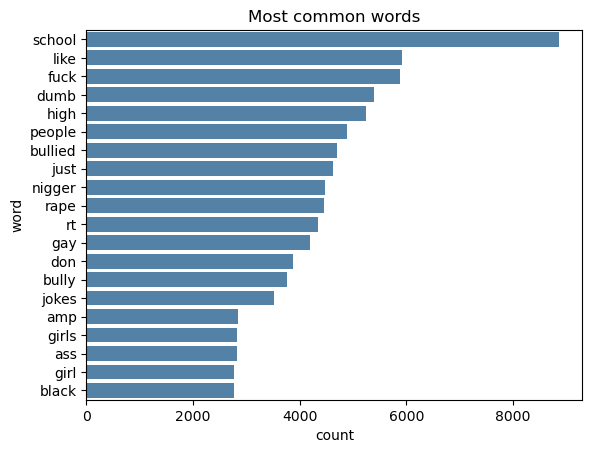

In [9]:
from sklearn.feature_extraction.text import CountVectorizer

vect = CountVectorizer(stop_words="english", max_features=20)
word_counts = vect.fit_transform(df["text"])
top_words = pd.DataFrame({
    "word": vect.get_feature_names_out(),
    "count": word_counts.sum(axis=0).A1,
}).sort_values("count", ascending=False)

sns.barplot(data=top_words, x="count", y="word", color="steelblue")
plt.title("Most common words")
plt.show()


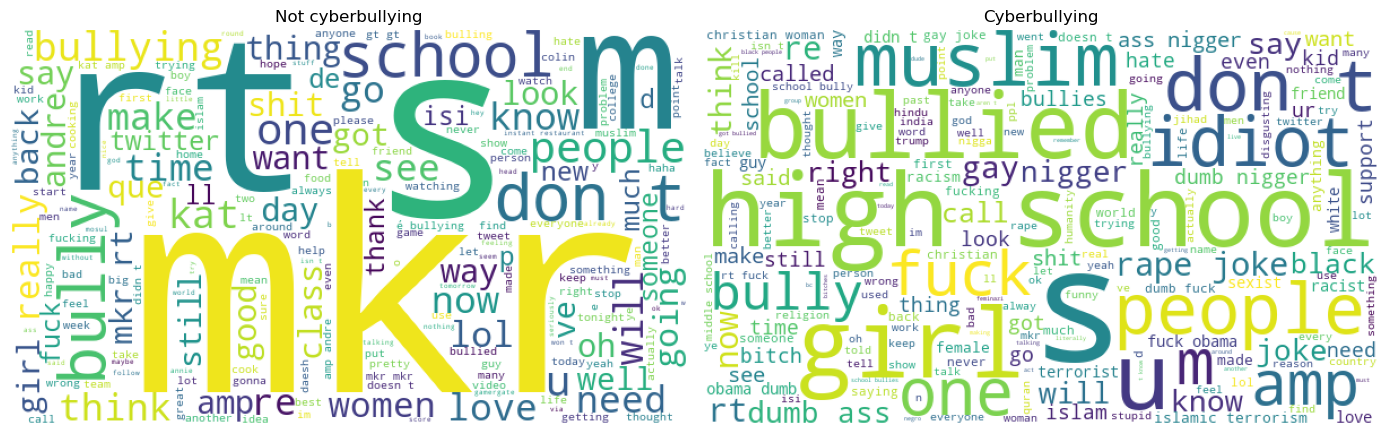

In [12]:
from wordcloud import WordCloud, STOPWORDS

ok_text = " ".join(df.loc[df["label"] == "not_cyberbullying", "text"].astype(str))
bad_text = " ".join(df.loc[df["label"] != "not_cyberbullying", "text"].astype(str))

plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.imshow(WordCloud(width=600, height=350, background_color="white", stopwords=STOPWORDS).generate(ok_text))
plt.title("Not cyberbullying")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(WordCloud(width=600, height=350, background_color="white", stopwords=STOPWORDS).generate(bad_text))
plt.title("Cyberbullying")
plt.axis("off")
plt.tight_layout()
plt.show()


In [13]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report

x = df["text"]
y = df["label"]
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.20, random_state=42, stratify=y
)

lr = Pipeline([
    ("vect", TfidfVectorizer(stop_words="english", max_features=5000)),
    ("model", LogisticRegression(max_iter=1000)),
])
lr.fit(x_train, y_train)
lr_pred = lr.predict(x_test)

print("Logistic Regression")
print(classification_report(y_test, lr_pred))


Logistic Regression
                     precision    recall  f1-score   support

                age       0.97      0.97      0.97      1598
          ethnicity       0.97      0.96      0.97      1592
             gender       0.91      0.83      0.87      1595
  not_cyberbullying       0.59      0.52      0.55      1589
other_cyberbullying       0.58      0.70      0.63      1565
           religion       0.96      0.94      0.95      1600

           accuracy                           0.82      9539
          macro avg       0.83      0.82      0.82      9539
       weighted avg       0.83      0.82      0.82      9539



In [14]:
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.preprocessing import LabelEncoder

tf.keras.utils.set_random_seed(42)

le = LabelEncoder()
y_tr = le.fit_transform(y_train)
y_te = le.transform(y_test)
n_class = len(le.classes_)

vectorize = layers.TextVectorization(max_tokens=10000, output_sequence_length=80)
vectorize.adapt(x_train.to_numpy())

dl = tf.keras.Sequential([
    vectorize,
    layers.Embedding(10000, 64, mask_zero=True),
    layers.Bidirectional(layers.LSTM(32)),
    layers.Dropout(0.3),
    layers.Dense(n_class, activation="softmax"),
])
dl.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
hist = dl.fit(
    x_train.to_numpy(), y_tr,
    validation_split=0.1,
    epochs=6,
    batch_size=64,
    callbacks=[EarlyStopping(patience=2, restore_best_weights=True)],
    verbose=1,
)

dl_pred = dl.predict(x_test.to_numpy(), verbose=0).argmax(axis=1)
print("Bidirectional LSTM")
print(classification_report(y_te, dl_pred, target_names=le.classes_))


Epoch 1/6
537/537 ━━━━━━━━━━━━━━━━━━━━ 9s 14ms/step - accuracy: 0.7303 - loss: 0.6993 - val_accuracy: 0.8124 - val_loss: 0.4474
Epoch 2/6
537/537 ━━━━━━━━━━━━━━━━━━━━ 8s 15ms/step - accuracy: 0.8491 - loss: 0.3798 - val_accuracy: 0.8218 - val_loss: 0.4235
Epoch 3/6
537/537 ━━━━━━━━━━━━━━━━━━━━ 9s 16ms/step - accuracy: 0.8774 - loss: 0.3138 - val_accuracy: 0.8147 - val_loss: 0.4633
Epoch 4/6
537/537 ━━━━━━━━━━━━━━━━━━━━ 9s 16ms/step - accuracy: 0.8976 - loss: 0.2632 - val_accuracy: 0.8160 - val_loss: 0.4866
Bidirectional LSTM
                     precision    recall  f1-score   support

                age       0.98      0.97      0.97      1598
          ethnicity       0.98      0.96      0.97      1592
             gender       0.87      0.85      0.86      1595
  not_cyberbullying       0.56      0.60      0.58      1589
other_cyberbullying       0.61      0.61      0.61      1565
           religion       0.96      0.95      0.95      1600

           accuracy                     

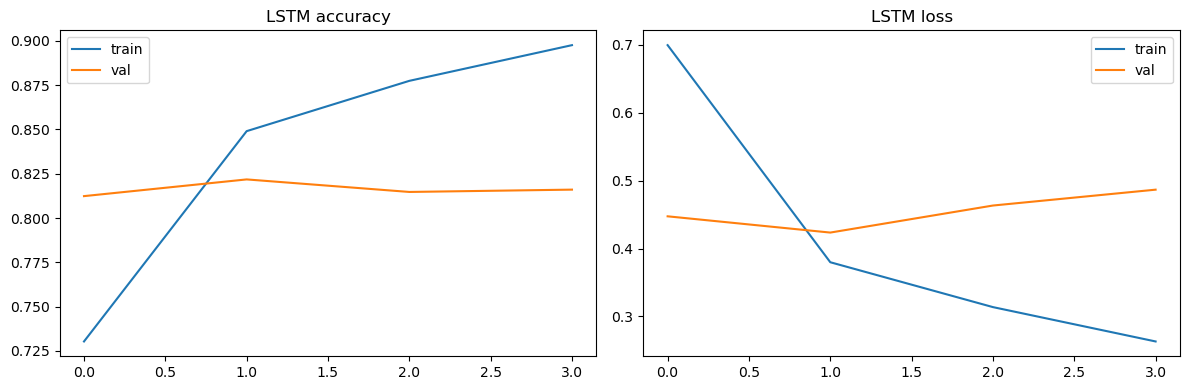

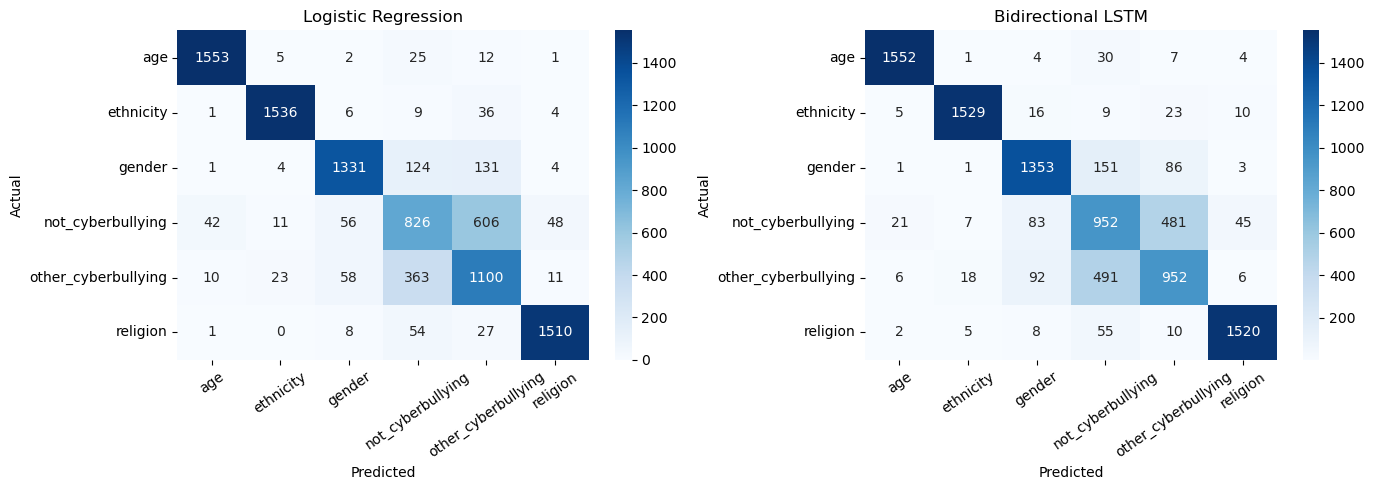

Logistic Regression accuracy 0.8235664115735402 macro F1 0.8240303783175899
LSTM                 accuracy 0.8237760771569347 macro F1 0.8245472354341503


In [15]:
from sklearn.metrics import confusion_matrix, f1_score, accuracy_score

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(hist.history["accuracy"], label="train")
plt.plot(hist.history["val_accuracy"], label="val")
plt.title("LSTM accuracy")
plt.legend()
plt.subplot(1, 2, 2)
plt.plot(hist.history["loss"], label="train")
plt.plot(hist.history["val_loss"], label="val")
plt.title("LSTM loss")
plt.legend()
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(
    confusion_matrix(y_test, lr_pred, labels=le.classes_),
    annot=True, fmt="d", cmap="Blues", ax=axes[0],
    xticklabels=le.classes_, yticklabels=le.classes_,
)
axes[0].set_title("Logistic Regression")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")
axes[0].tick_params(axis="x", rotation=35)
sns.heatmap(
    confusion_matrix(y_te, dl_pred),
    annot=True, fmt="d", cmap="Blues", ax=axes[1],
    xticklabels=le.classes_, yticklabels=le.classes_,
)
axes[1].set_title("Bidirectional LSTM")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")
axes[1].tick_params(axis="x", rotation=35)
plt.tight_layout()
plt.show()

print("Logistic Regression accuracy", accuracy_score(y_test, lr_pred), "macro F1", f1_score(y_test, lr_pred, average="macro"))
print("LSTM                 accuracy", accuracy_score(y_te, dl_pred), "macro F1", f1_score(y_te, dl_pred, average="macro"))


In [17]:
samples = [
    "had a good game last night thanks for coming",
    "kids that age should not even be on this app they are so stupid",
]
print("Logistic Regression", lr.predict(samples))
print("LSTM               ", le.inverse_transform(dl.predict(tf.constant(samples), verbose=0).argmax(axis=1)))


Logistic Regression ['not_cyberbullying' 'other_cyberbullying']
LSTM                ['not_cyberbullying' 'other_cyberbullying']


In [18]:
dl.save("cyberbullying.keras")


# Conclusion

The class plot shows six balanced labels. The word-count bar and the two word clouds show how ordinary tweets differ from bullying tweets before any model runs. Logistic Regression on TF-IDF is a strong baseline for this multiclass text. The Bidirectional LSTM is the deep learning model: it learns embeddings and reads each tweet in both directions. Macro F1 is the number to watch, not a single class score. The LSTM is saved as cyberbullying.keras.
